# 결과 요약 (2026-11-03)
따라하기 01~04와 확장 연구의 핵심 결과를 한곳에 모은다. 이 노트북은 백테스트를 다시 돌리지 않고 각 노트북이 남긴 파일만 읽는다(1-1·4·5절은 그 파일의 월수익률로 성과 지표만 그 자리에서 계산). `결과_월수익률/요약표.csv`는 예전 데이터(2026-11-02) 결과라 쓰지 않는다.
그래서 **먼저 따라하기 01~04와 `연구/확장연구_20261103.ipynb`를 실행해야** 이 노트북의 숫자가 최신이 된다(각 칸 위에 어느 노트북이 만든 파일인지 적었다).

| 파일 | 만든 노트북 |
|---|---|
| `결과_월수익률/01_우동호2023.pkl`, `01_원문대조.csv` | `따라하기/01_우동호2023.ipynb` |
| `결과_월수익률/02_NH밸류.pkl`, `02_원문대조_그림19.csv`, `02_원문주장.csv` | `따라하기/02_NH_밸류.ipynb` |
| `결과_월수익률/03_NH퀄리티로우볼.pkl`, `03_원문판정.csv` | `따라하기/03_NH_퀄리티로우볼.ipynb` |
| `결과_월수익률/04_신마법공식.pkl`, `04_NovyMarx대조.csv` | `따라하기/04_신마법공식.ipynb` |
| `연구/결과/확장연구_20261103.pkl`, `.csv` | `연구/확장연구_20261103.ipynb` |

데이터: DataGuide에서 새로 통째로 받은 일간 파일(`data\통합_전체_202611`, 1988-01-04~2026-09-30, 코스피+코스닥 상장폐지 포함). 데이터 규칙과 한계는 `README.md`.
줄임말: EW(동일가중), VW(시가총액가중), MDD(최대 낙폭), IR(정보비율), NW(뉴이-웨스트 t), LS(롱숏), TR(배당 포함 수정주가).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "공통"))
import pandas as pd
import 평가
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)
폴더 = 평가.결과폴더
읽기csv = lambda n, **k: pd.read_csv(폴더 / n, encoding="utf-8-sig", **k)
for f in sorted(폴더.glob("*.*")) + sorted((Path.cwd() / "결과").glob("확장연구_20261103.*")):
    print(f"{pd.Timestamp(f.stat().st_mtime, unit='s', tz='UTC').tz_convert('Asia/Seoul'):%Y-%m-%d %H:%M}  {f.name}")

2026-11-03 10:35  01_우동호2023.pkl
2026-11-03 10:35  01_원문대조.csv
2026-11-03 11:41  02_NH밸류.pkl
2026-11-03 11:24  02_원문대조_그림19.csv
2026-11-03 11:24  02_원문주장.csv
2026-11-03 10:56  03_NH퀄리티로우볼.pkl
2026-11-03 10:52  03_원문판정.csv
2026-11-03 10:38  04_NovyMarx대조.csv
2026-11-03 10:38  04_신마법공식.pkl
2026-11-02 14:22  요약표.csv
2026-11-03 15:19  확장연구_20261103.csv
2026-11-03 15:19  확장연구_20261103.pkl


## 1. 우동호 외(2023) 재현 — 원문 표 2~7 vs 우리 (본문 설정)
2004-04~2022-03, 4월 첫 거래일 리밸런싱, 상위 30종목 동일가중, 벤치마크 코스피(원문 p.513 "벤치마크 수익률은 KOSPI수익률을 사용한다"). 누적·MDD·표준편차는 소수(9.8 = 980%). 이 표의 Jensen t·3F t·4F t는 원문처럼 OLS t이고, 1-1절의 'Carhart t(NW)'는 뉴이-웨스트 t다.

In [2]:
읽기csv("01_원문대조.csv", header=[0, 1], index_col=[0, 1])

Return              MDD             SD        Sharpe            IR         Jensen α         Jensen t            3F α            3F t            4F α            4F t        
                  원문       우리      원문      우리     원문     우리     원문     우리     원문      우리       원문      우리       원문      우리      원문      우리      원문      우리      원문      우리      원문      우리
전체    MF      9.8035   7.3090 -0.5034 -0.5911 0.9479 0.2613 2.4200 0.4683 1.4800  0.4040   0.0068  0.0059   2.3200  1.6920 -0.0050  0.0025 -1.2800  0.8361 -0.0053  0.0026 -1.3400  0.8924
      IMF    10.2791  12.9303 -0.4962 -0.5465 0.8857 0.2413 2.5800 0.6026 1.5700  0.5558   0.0071  0.0083   2.4700  2.4837 -0.0028  0.0049 -0.7300  1.8735 -0.0034  0.0049 -0.8700  1.8720
      KOSPI   2.1239   2.1038 -0.5454 -0.5062 0.8349 0.1917 1.3400 0.2687 0.0000     NaN      NaN  0.0000      NaN     NaN     NaN  0.0000     NaN     NaN     NaN  0.0000     NaN     NaN
시총1분위 MF     44.2427 212.1018 -0.5760 -0.5573 1.1082 0.2885 3.5200 1.0802 2.7200  1.1615   0.0137  0.0219   3.8800  4.9541  0.0139  0.0175  3.5100  4.9778  0.0141  0.0177  3.5500  4.9847
      IMF   101.3052 354.8223 -0.6203 -0.5460 1.1828 0.3030 4.0600 1.1357 3.3100  1.2003   0.0179  0.0247   4.3900  5.1233  0.0167  0.0207  3.6200  5.5591  0.0168  0.0205  3.6400  5.4335
시총2분위 MF     17.6391  20.2121 -0.5155 -0.6225 1.0596 0.2801 2.7800 0.6378 1.9400  0.6580   0.0095  0.0104   2.7600  2.7144  0.0097  0.0044  2.7000  1.9032  0.0096  0.0051  2.6900  2.1925
      IMF    28.4832  24.5319 -0.5343 -0.6301 1.1032 0.2840 3.1300 0.6697 2.3200  0.6951   0.0120  0.0113   3.1300  2.8763  0.0127  0.0056  3.2500  2.2736  0.0126  0.0055  3.2400  2.1942
시총3분위 MF      6.3007   4.7286 -0.4963 -0.5834 0.9663 0.2645 1.9900 0.3850 1.0700  0.2942   0.0049  0.0040   1.6800  1.1755  0.0044 -0.0001  1.4600 -0.0525  0.0044 -0.0002  1.4500 -0.0886
      IMF     9.8866   4.8274 -0.4799 -0.5877 0.9275 0.2605 2.4700 0.3900 1.5100  0.2946   0.0068  0.0040   2.3800  1.2054  0.0066  0.0003  2.2200  0.1194  0.0066 -0.0000  2.2100 -0.0114
시총4분위 MF      2.0623   1.4013 -0.5528 -0.5156 0.9325 0.2368 1.1000 0.1979 0.1400 -0.0306   0.0009 -0.0002   0.3300 -0.0566  0.0005 -0.0034  0.1800 -1.4329  0.0004 -0.0038  0.1300 -1.6151
      IMF     2.7631   3.9618 -0.5583 -0.5189 0.9242 0.2266 1.3200 0.3736 0.3500  0.2234   0.0020  0.0032   0.6800  1.1000  0.0031  0.0004  0.9900  0.1654  0.0028 -0.0004  0.9000 -0.1911
시총5분위 MF      3.3954   1.5809 -0.4398 -0.5085 0.7890 0.2012 1.5900 0.2151 0.4700 -0.0761   0.0022 -0.0002   1.1300 -0.1047  0.0004 -0.0015  0.2000 -0.7233 -0.0003 -0.0016 -0.1500 -0.7394
      IMF     3.7548   2.6300 -0.3496 -0.4532 0.6953 0.1824 1.8200 0.3215 0.5400  0.0616   0.0028  0.0016   1.4700  0.7477  0.0018  0.0009  0.8600  0.4424  0.0011  0.0007  0.5700  0.3289

### 1-1. 우리 결과: 본문·확인판(발표일 규칙)·A070480 빼기, EW·VW

In [3]:
d = pd.read_pickle(폴더 / "01_우동호2023.pkl")
R = d["R"].copy(); R[("KOSPI", "-")] = d["F"]["시장"]
평가.성과표(R.dropna(how="all"), d["F"])[["개월", "누적", "연환산", "표준편차(연)", "샤프", "MDD", "정보비율", "CAPM α(월)", "Carhart α(월)", "Carhart t(NW)"]]

개월      누적    연환산  표준편차(연)     샤프     MDD   정보비율  CAPM α(월)  Carhart α(월)  Carhart t(NW)
MF            동일 216.0000  7.3090 0.1248   0.2613 0.4683 -0.5911 0.4040     0.0059        0.0026         0.9121
              시총 216.0000  9.3213 0.1385   0.3010 0.4786 -0.6112 0.3822     0.0080        0.0065         1.4482
IMF           동일 216.0000 12.9303 0.1576   0.2413 0.6026 -0.5465 0.5558     0.0083        0.0049         1.7540
              시총 216.0000 14.3933 0.1640   0.2308 0.6446 -0.3405 0.5158     0.0092        0.0071         1.8837
MF_확인판        동일 216.0000  6.9775 0.1223   0.2613 0.4598 -0.5879 0.3836     0.0058        0.0024         0.8149
              시총 216.0000  7.7551 0.1281   0.3110 0.4406 -0.6058 0.3266     0.0076        0.0060         1.2606
IMF_확인판       동일 216.0000 11.2813 0.1495   0.2462 0.5659 -0.5465 0.5069     0.0077        0.0046         1.6072
              시총 216.0000 16.1707 0.1711   0.2382 0.6568 -0.3405 0.5513     0.0097        0.0069         1.7820
MF_A070480빼기  동일 216.0000  7.3090 0.1248   0.2613 0.4683 -0.5911 0.4040     0.0059        0.0026         0.9121
              시총 216.0000  9.3213 0.1385   0.3010 0.4786 -0.6112 0.3822     0.0080        0.0065         1.4482
IMF_A070480빼기 동일 216.0000 12.9303 0.1576   0.2413 0.6026 -0.5465 0.5558     0.0083        0.0049         1.7540
              시총 216.0000 14.3933 0.1640   0.2308 0.6446 -0.3405 0.5158     0.0092        0.0071         1.8837
KOSPI         -  216.0000  2.1038 0.0649   0.1917 0.2687 -0.5062    NaN     0.0000        0.0000            NaN

## 2. NH 밸류(2018) — 그림 19 위험조정수익률, 원문 주장

In [4]:
display(읽기csv("02_원문대조_그림19.csv", index_col=0))
읽기csv("02_원문주장.csv", index_col=0)

,원문 그림19,우리(Q1 월평균/월표준편차)
Multi-Metric,0.3900,0.3302
P/B,0.3400,0.3343
P/E,0.3200,0.2949
EV/EBITDA,0.3400,0.2940
P/S,0.3000,0.2926
P/OCF,0.2900,0.3164


,원문 주장,우리
0,모든 지표에서 LS 누적이 양(+),True
1,P/B·P/E가 가장 효과적(LS 누적 상위 2),False
2,Multi-Metric 1분위가 단일 지표 1분위보다 위험조정수익률 높음,False


## 3. NH 퀄리티·로우볼(2018) — 원문 주장 판정 (다시 돌린 결과)
'확인판(자본>0만)' 칸은 ROE·부채비율을 자본이 0보다 큰 종목만으로 계산한 것이다. 두 칸이 다르면 그 판정은 음수 자본 처리에 달려 있다.

In [5]:
읽기csv("03_원문판정.csv", index_col=0)

,우리,확인판(자본>0만),확인판(보통주만)
원문 주장,,,
4개 퀄리티 지표 모두 2~4분위 누적이 가장 높음,False,False,NaN
4개 퀄리티 지표 모두 5분위 누적이 가장 낮음,True,True,NaN
로우볼 LS 누적이 양(+),True,True,True
로우볼: 6·12개월 리밸런싱 LS 누적 > 3개월,True,True,NaN


## 4. 신마법공식(PBR + GP/A)과 Novy-Marx(2013) 표 7 참고판

In [6]:
d = pd.read_pickle(폴더 / "04_신마법공식.pkl")
R = d["R"].copy(); R[("KOSPI", "-")] = d["F"]["시장"]
display(평가.성과표(R.dropna(how="all"), d["F"])[["개월", "누적", "연환산", "샤프", "MDD", "정보비율", "Carhart α(월)", "Carhart t(NW)"]])
읽기csv("04_NovyMarx대조.csv", header=[0, 1], index_col=0)

개월      누적    연환산     샤프     MDD   정보비율  Carhart α(월)  Carhart t(NW)
신마법공식  동일 216.0000 44.1046 0.2357 0.8482 -0.5487 0.8834        0.0073         3.1724
       시총 216.0000  8.4692 0.1330 0.5218 -0.5396 0.4081        0.0019         0.6750
우동호IMF 동일 216.0000 12.9303 0.1576 0.6026 -0.5465 0.5558        0.0049         1.7540
       시총 216.0000 14.3933 0.1640 0.6446 -0.3405 0.5158        0.0071         1.8837
KOSPI  -  216.0000  2.1038 0.0649 0.2687 -0.5062    NaN        0.0000            NaN

월 초과수익(%)                             t                      FF3 α(%)                         FF3 t       
     원문(미국 1963-07~2009-12)     우리 원문(미국 1963-07~2009-12)     우리 원문(미국 1963-07~2009-12)     우리 원문(미국 1963-07~2009-12)     우리
High                 0.7800 1.1246                 3.6800 2.8651                 0.1600 0.3473                 2.6900 2.0961
H-L                  0.6400 0.9508                 5.2100 4.0886                 0.3900 0.5204                 3.7700 2.9716

## 5. 따라하기 전체 요약표: 전략 × 가중 × 기간 (`평가.요약`)

In [7]:
요약 = 평가.요약()
요약

보유 첫 달   보유 끝 달   개월 평균(월 초과) 평균 t(NW)      샤프     MDD Carhart α(월) α t(NW)
파일          전략                   가중 기간                                                                                           
01_우동호2023  MF                   동일 전체               2004-04  2022-03  216   0.0102   1.8831  0.4683 -0.5911       0.0026  0.9121
                                    2004-04~2017-03  2004-04  2017-03  156   0.0106   1.5533  0.4732 -0.5911       0.0014  0.3408
                                    2017-04~         2017-04  2022-03   60   0.0093   1.1112  0.4519 -0.3136       0.0023  0.6084
                                 시총 전체               2004-04  2022-03  216   0.0120   2.0260  0.4786 -0.6112       0.0065  1.4482
                                    2004-04~2017-03  2004-04  2017-03  156   0.0123   1.6230  0.4746 -0.6112       0.0069  1.1170
                                    2017-04~         2017-04  2022-03   60   0.0112   1.3572  0.4895 -0.2759       0.0057  1.1181
            IMF                  동일 전체               2004-04  2022-03  216   0.0121   2.3277  0.6026 -0.5465       0.0049  1.7540
                                    2004-04~2017-03  2004-04  2017-03  156   0.0131   1.9759  0.6386 -0.5465       0.0028  0.8059
                                    2017-04~         2017-04  2022-03   60   0.0095   1.2714  0.4986 -0.2110       0.0029  0.6983
                                 시총 전체               2004-04  2022-03  216   0.0124   3.0700  0.6446 -0.3405       0.0071  1.8837
                                    2004-04~2017-03  2004-04  2017-03  156   0.0137   2.7661  0.7269 -0.3405       0.0067  1.2790
                                    2017-04~         2017-04  2022-03   60   0.0090   1.3225  0.4427 -0.2485       0.0026  0.5504
            MF_확인판               동일 전체               2004-04  2022-03  216   0.0100   1.8647  0.4598 -0.5879       0.0024  0.8149
                                    2004-04~2017-03  2004-04  2017-03  156   0.0105   1.5530  0.4669 -0.5879       0.0011  0.2614
                                    2017-04~         2017-04  2022-03   60   0.0089   1.0706  0.4373 -0.3202       0.0018  0.4840
                                 시총 전체               2004-04  2022-03  216   0.0114   1.8805  0.4406 -0.6058       0.0060  1.2606
                                    2004-04~2017-03  2004-04  2017-03  156   0.0115   1.4749  0.4254 -0.6058       0.0061  0.9340
                                    2017-04~         2017-04  2022-03   60   0.0111   1.3544  0.4889 -0.2767       0.0056  1.1023
            IMF_확인판              동일 전체               2004-04  2022-03  216   0.0116   2.2006  0.5659 -0.5465       0.0046  1.6072
                                    2004-04~2017-03  2004-04  2017-03  156   0.0127   1.8679  0.5986 -0.5465       0.0028  0.7493
                                    2017-04~         2017-04  2022-03   60   0.0089   1.2197  0.4698 -0.2204       0.0022  0.5660
                                 시총 전체               2004-04  2022-03  216   0.0130   2.8490  0.6568 -0.3405       0.0069  1.7820
                                    2004-04~2017-03  2004-04  2017-03  156   0.0146   2.5295  0.7406 -0.3405       0.0062  1.1680
                                    2017-04~         2017-04  2022-03   60   0.0090   1.3175  0.4413 -0.2486       0.0025  0.5416
            MF_A070480빼기         동일 전체               2004-04  2022-03  216   0.0102   1.8831  0.4683 -0.5911       0.0026  0.9121
                                    2004-04~2017-03  2004-04  2017-03  156   0.0106   1.5533  0.4732 -0.5911       0.0014  0.3408
                                    2017-04~         2017-04  2022-03   60   0.0093   1.1112  0.4519 -0.3136       0.0023  0.6084
                                 시총 전체               2004-04  2022-03  216   0.0120   2.0260  0.4786 -0.6112       0.0065  1.4482
                                    2004-04~2017-03  2004-04  2017-03  156   0.0123   1.6230  0.4746 -0.6112       0.0069  1.1170
                        

## 6. 확장 연구 핵심 결과
우동호 유니버스, 배당 포함 가격, 1990-04~2026-09. 주 벤치마크 = 유니버스 시가총액 가중(비용 0). 자세한 표와 설정·근거는 `연구/확장연구_20261103.ipynb`.
- **α 읽을 때**: 시장 요인은 코스피 가격지수(배당 없음)라 배당 포함 포트폴리오의 α에 배당만큼이 섞인다. 전략 없이 유니버스를 시총가중으로 들고만 있어도 Carhart α가 양수로 나온다(확장연구 4절 벤치마크 줄). α는 유니버스 벤치마크 줄과 견주어 본다.
- **여러 조합에서 고름(과최적화)**: 수익률 열이 2,880개(전략 48 × 비중 5 × 주기 4 × 비용 3)다. 그중 '상위'를 고르면 우연히 좋은 것이 뽑힐 수 있고, 여러 번 검정한 것에 대한 t 보정은 하지 않았다. 단계별 순서 전략은 근거 없는 '남길 비율 0.5'에 달려 있다. 그래서 상위 목록보다 6-2(중앙값)·6-3(기간별 일관성)을 함께 본다.

In [8]:
x = pd.read_pickle(Path.cwd() / "결과" / "확장연구_20261103.pkl")
표 = x["표"]
전체 = 표.xs("전체", level="기간")
기본 = 전체.xs("비용기본", level="비용")
print(f"전략 {len(x['전략들'])}개, 결과표 {len(표)}줄")
display(표.loc[[i for i in 표.index if i[0].startswith("벤치:")]].xs("전체", level="기간").droplevel([1, 2, 3]).style.set_caption("벤치마크(전체 기간)").format(precision=4))
기본.loc["EY+ROC 순위합산"]["샤프"].unstack("주기").style.set_caption("마법공식(EY+ROC 순위합산): 비중 × 주기 샤프, 전체 기간, 기본 비용").format(precision=3)

전략 48개, 결과표 14427줄


,개월,누적,연환산,표준편차(연),벤치 대비 연환산,샤프,MDD,정보비율,CAPM α(월),CAPM t(OLS),CAPM t(NW),FF3 α(월),FF3 t(OLS),FF3 t(NW),Carhart α(월),Carhart t(OLS),Carhart t(NW),Carhart β:MKT,Carhart β:SMB,Carhart β:HML,Carhart β:MOM,Carhart adj R²,회전율(전 기간)
전략,,,,,,,,,,,,,,,,,,,,,,,
벤치:유니버스(시총가중),437.0000,18.6072,0.0851,0.2724,0.0000,0.2231,-0.6101,nan,0.0021,2.7314,2.7558,0.0035,5.4685,5.8939,0.0032,5.1343,5.1880,0.9972,0.0497,-0.1604,0.0611,0.9739,nan
벤치:코스피,437.0000,7.1545,0.0593,0.2697,-0.0258,0.1327,-0.7243,-0.4442,0.0000,nan,nan,0.0000,nan,nan,0.0000,nan,nan,1.0000,-0.0000,-0.0000,-0.0000,1.0000,nan
벤치:코스피TR,188.0000,3.3359,0.0982,0.2186,0.0030,0.4375,-0.3123,0.0729,0.0015,5.9605,7.3675,0.0015,5.9083,7.2739,0.0015,5.8631,7.4199,0.9990,0.0042,-0.0035,-0.0010,0.9971,nan
벤치:코스닥,362.0000,-0.1788,-0.0065,0.3253,-0.0996,0.0151,-0.8904,-0.3721,-0.0040,-1.0988,-1.0963,0.0005,0.1755,0.2041,0.0005,0.1914,0.2081,0.9362,0.6686,-0.5241,-0.0053,0.7287,nan
벤치:코스닥TR,188.0000,0.7567,0.0366,0.2229,-0.0585,0.1771,-0.3922,-0.3326,-0.0011,-0.3217,-0.3379,0.0014,0.6817,0.7366,0.0018,0.8869,0.9923,0.8687,0.7670,-0.5303,-0.0736,0.8275,nan
벤치:KRX TMI,197.0000,3.2605,0.0923,0.2187,-0.0118,0.4132,-0.3349,-0.4177,0.0003,0.8871,0.7868,0.0006,1.7750,1.5683,0.0006,1.5891,1.4067,1.0142,0.0354,-0.0399,0.0107,0.9941,nan


주기,1,3,6,12
비중,,,,
동일,0.416,0.384,0.317,0.295
시총,0.282,0.244,0.185,0.187
시총상한,0.183,0.159,0.145,0.150
위험균형,0.401,0.377,0.397,0.371
최소분산,0.311,0.335,0.401,0.229


### 6-1. 동일가중·12개월·기본 비용: 샤프 상위 10 전략과 기준(전체 기간)

In [9]:
k = 기본.xs(("동일", 12), level=["비중", "주기"]).sort_values("샤프", ascending=False)
k = k.assign(순위=range(1, len(k) + 1))
pd.concat([k.head(10), k.loc[["EY+ROC 순위합산"]]]).pipe(lambda t: t[~t.index.duplicated()])  # 같은 전략이 두 번 나오면 하나만(감사 L11)

,개월,누적,연환산,표준편차(연),벤치 대비 연환산,샤프,MDD,정보비율,CAPM α(월),CAPM t(OLS),CAPM t(NW),FF3 α(월),FF3 t(OLS),FF3 t(NW),Carhart α(월),Carhart t(OLS),Carhart t(NW),Carhart β:MKT,Carhart β:SMB,Carhart β:HML,Carhart β:MOM,Carhart adj R²,회전율(전 기간),순위
전략,,,,,,,,,,,,,,,,,,,,,,,,
GPA→EP,437.0000,1730.6839,0.2272,0.4014,0.1421,0.5394,-0.6574,0.4483,0.0159,3.2680,2.8446,0.0168,4.2382,2.6239,0.0169,4.2393,2.4220,0.9403,1.0001,-0.2145,-0.0152,0.5095,0.7960,1
ROC→EBITDA_EV,437.0000,877.9528,0.2046,0.3353,0.1194,0.5345,-0.5117,0.4210,0.0130,3.2992,3.0150,0.0147,4.7589,3.1725,0.0144,4.6288,2.8773,0.8445,0.8330,-0.2765,0.0625,0.5743,0.6831,2
영업CF자산→EBITDA_EV,437.0000,1033.2817,0.2100,0.3542,0.1248,0.5341,-0.5757,0.4479,0.0136,3.3245,2.8447,0.0156,4.6899,2.9176,0.0151,4.5289,2.6714,0.9019,0.8149,-0.3069,0.0895,0.5593,0.6954,3
ROE→EP,437.0000,1071.0250,0.2112,0.3788,0.1260,0.5292,-0.6545,0.4395,0.0145,3.2729,2.8601,0.0132,3.8388,2.8323,0.0129,3.7586,2.6534,0.9806,1.0006,0.0306,0.0379,0.5903,0.8626,4
ROE→EBITDA_EV,437.0000,959.1090,0.2075,0.3634,0.1224,0.5210,-0.6007,0.4249,0.0137,3.1888,2.7976,0.0157,4.5213,2.8423,0.0152,4.3690,2.6111,0.8933,0.8646,-0.3114,0.0870,0.5436,0.6917,5
GPA→EBITDA_EV,437.0000,949.0601,0.2072,0.3660,0.1220,0.5157,-0.4876,0.4148,0.0137,3.1331,2.7043,0.0161,4.5482,2.7484,0.0158,4.4525,2.5246,0.8783,0.8655,-0.3543,0.0476,0.5312,0.6889,6
영업CF자산→EP,437.0000,1016.1490,0.2094,0.3865,0.1243,0.5111,-0.6707,0.4045,0.0144,3.0712,2.6336,0.0151,3.8423,2.4218,0.0148,3.7384,2.1508,0.8904,0.9198,-0.1745,0.0614,0.4801,0.8312,7
EP+영업CF자산 순위합산,437.0000,1068.1670,0.2111,0.3905,0.1259,0.5044,-0.5716,0.4051,0.0143,3.0377,2.6377,0.0162,4.0546,2.4593,0.0159,3.9774,2.1914,0.9062,0.8778,-0.2990,0.0411,0.4782,0.8500,8
GPA→영업이익_EV,437.0000,592.6157,0.1917,0.3617,0.1065,0.4866,-0.6053,0.3804,0.0126,2.9453,2.4914,0.0145,4.3389,2.6968,0.0142,4.2248,2.4978,0.9004,0.9148,-0.3012,0.0576,0.5727,0.6897,9


### 6-2. 비중 방식 × 주기: 전 전략 샤프 중앙값 / 거래비용 민감도(연환산 중앙값)

In [10]:
전략줄 = lambda t: t.drop(index=[i for i in t.index if i[0].startswith("벤치:")])
display(전략줄(표.xs(("공통", "비용기본"), level=["기간", "비용"]))["샤프"].groupby(["비중", "주기"]).median().unstack("주기").style.set_caption("샤프 중앙값('공통' 기간: 모든 비중 방식이 같은 달부터)").format(precision=3))
전략줄(전체)["연환산"].groupby(["주기", "비용"]).median().unstack("비용")[["비용0", "비용기본", "비용2배"]].style.set_caption("연환산 수익률 중앙값").format(precision=4)

주기,1,3,6,12
비중,,,,
동일,0.604,0.572,0.446,0.414
시총,0.371,0.348,0.287,0.378
시총상한,0.376,0.368,0.283,0.335
위험균형,0.557,0.521,0.452,0.450
최소분산,0.463,0.413,0.423,0.384


비용,비용0,비용기본,비용2배
주기,,,
1,0.1902,0.1558,0.1205
3,0.1736,0.1509,0.1287
6,0.1496,0.1329,0.1175
12,0.1461,0.1341,0.1228


### 6-3. 기간별 일관성: 동일가중·12개월·기본 비용에서 유니버스 벤치마크보다 샤프가 높은 전략 수

In [11]:
b = 표.xs(("벤치:유니버스(시총가중)", "-", 0, "비용0"), level=[0, 1, 2, 3])["샤프"]
s = 전략줄(표).xs(("동일", 12, "비용기본"), level=["비중", "주기", "비용"])["샤프"].unstack("기간")
pd.DataFrame({"전략 수": s.notna().sum(), "벤치마크보다 샤프 높음": (s.gt(b)).sum(), "벤치마크 샤프": b}).T

기간,1990-04~2004-03,2004-04~2017-03,2017-04~,공통,전체
전략 수,48.0000,48.0000,48.0000,48.0000,48.0000
벤치마크보다 샤프 높음,48.0000,35.0000,0.0000,39.0000,44.0000
벤치마크 샤프,-0.0296,0.3951,0.5587,0.2967,0.2231


## 7. 리포트에 쓸 핵심 표·그림 (`결과_전략수익률/`, `연구/확장연구_20261103.ipynb` 6절이 만듦)
기준 = 마법공식(EY+ROC 순위합산), 동일가중, 12개월, 기본 비용. 비교마다 조건 하나만 바꿨다. 표 아래 문장은 그 표의 숫자에서 코드가 만든다(가장 높은·낮은 줄을 그대로 옮김, 해석 없음).
칸: 연환산 = 기하 연환산 수익률, 표준편차(연) = 월 표준편차 × √12, 샤프 = 월 초과수익(콜금리 차감) 평균/표준편차 × √12, MDD = 최대 낙폭, 회전율 = 리밸런싱당 평균 한쪽 회전율(전 기간), 벤치 대비 연환산 = 같은 달들의 유니버스 시총가중 벤치마크와 연환산 차이, 정보비율 = 유니버스 벤치마크 대비. α·t는 코스피 가격지수(배당 없음) 기준이라 배당 포함 포트폴리오에서는 배당만큼 높게 나온다(6절).

[비중 방식 (공통 기간)] 줄 5개. 샤프 가장 높음: EY+ROC 순위합산 / 위험균형 / 12 (0.340), 가장 낮음: EY+ROC 순위합산 / 시총상한 / 12 (0.169). 연환산 가장 높음: EY+ROC 순위합산 / 위험균형 / 12 (11.62%). MDD 가장 얕음: EY+ROC 순위합산 / 동일 / 12 (-71.91%).
  같은 기간 유니버스 시총가중 벤치마크보다 샤프가 높은 줄: 1/5개 (벤치 샤프 공통 0.297)


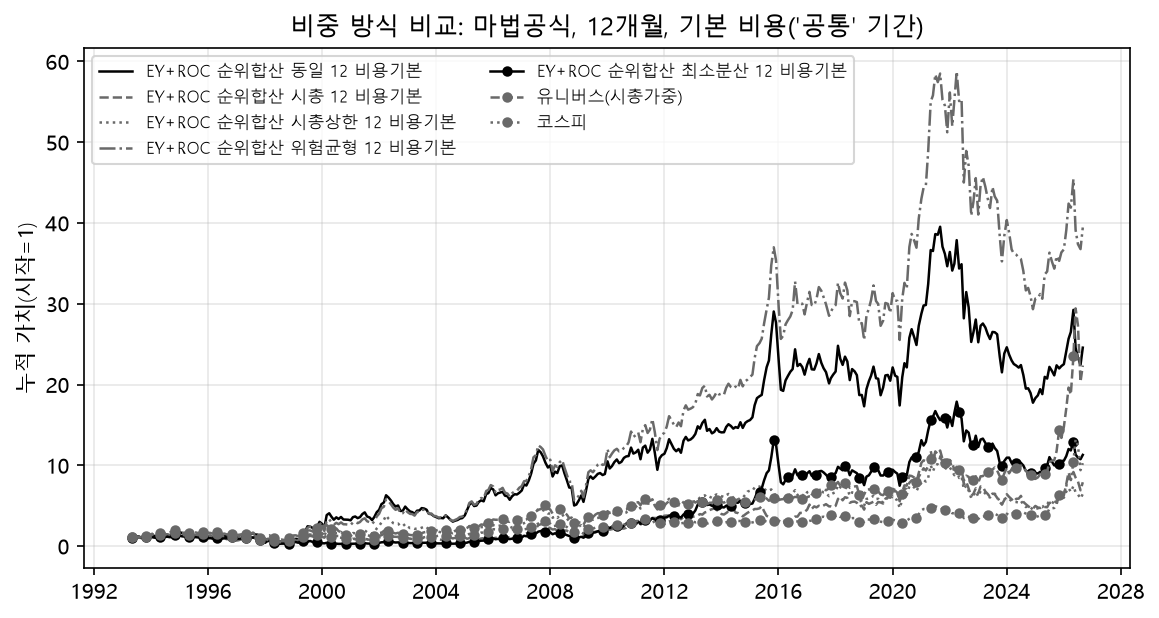

[리밸런싱 주기] 줄 4개. 샤프 가장 높음: EY+ROC 순위합산 / 동일 / 1 (0.416), 가장 낮음: EY+ROC 순위합산 / 동일 / 12 (0.295). 연환산 가장 높음: EY+ROC 순위합산 / 동일 / 1 (15.33%). MDD 가장 얕음: EY+ROC 순위합산 / 동일 / 3 (-56.27%).
  같은 기간 유니버스 시총가중 벤치마크보다 샤프가 높은 줄: 4/4개 (벤치 샤프 전체 0.223)


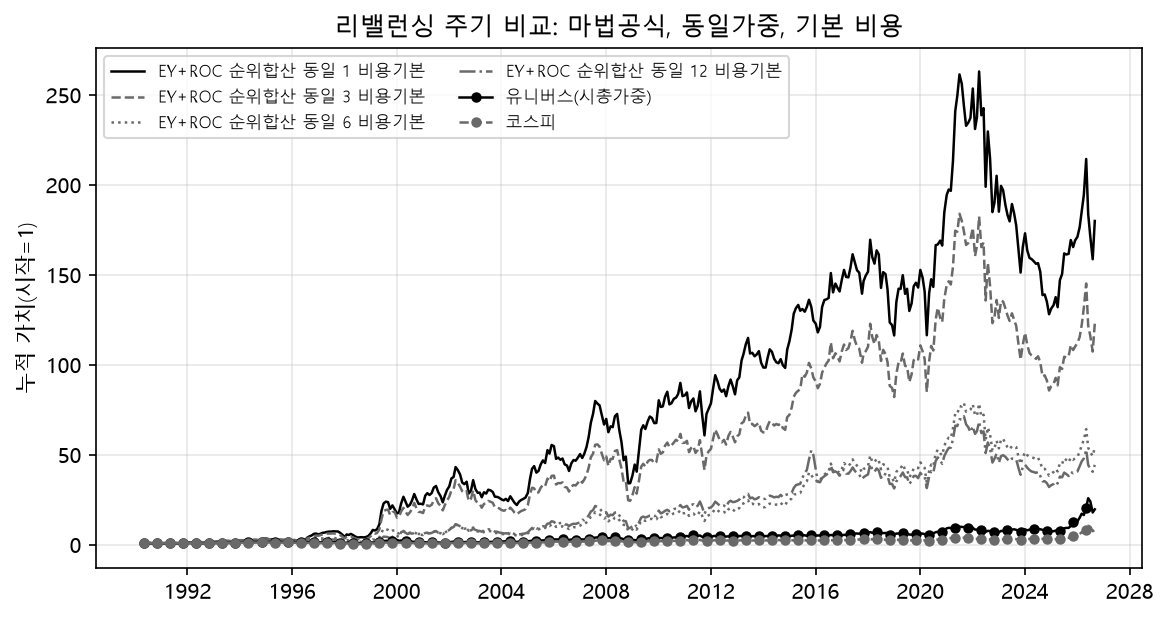

[지표 바꾸기 (순위합산)] 줄 16개. 샤프 가장 높음: EP+영업CF자산 순위합산 / 동일 / 12 (0.504), 가장 낮음: EY+ROC 순위합산 / 동일 / 12 (0.295). 연환산 가장 높음: EP+영업CF자산 순위합산 / 동일 / 12 (21.11%). MDD 가장 얕음: EBITDA_EV+영업CF자산 순위합산 / 동일 / 12 (-51.72%).
  같은 기간 유니버스 시총가중 벤치마크보다 샤프가 높은 줄: 16/16개 (벤치 샤프 전체 0.223)


,,,,,개월,연환산,표준편차(연),샤프,MDD,회전율(전 기간),벤치 대비 연환산,정보비율,Carhart α(월),Carhart t(NW)
전략,비중,주기,비용,기간,,,,,,,,,,
EY+ROC 순위합산,동일,12,비용기본,전체,437.0000,0.1097,0.3334,0.2948,-0.7191,0.8131,0.0246,0.1337,0.0072,1.8668
EY+GPA 순위합산,동일,12,비용기본,전체,437.0000,0.1576,0.3280,0.4211,-0.6517,0.6507,0.0725,0.2815,0.0103,2.7540
EY+ROE 순위합산,동일,12,비용기본,전체,437.0000,0.1190,0.3544,0.3168,-0.5821,0.8467,0.0339,0.1708,0.0090,2.1981
EY+영업CF자산 순위합산,동일,12,비용기본,전체,437.0000,0.1732,0.3429,0.4523,-0.5514,0.8161,0.0880,0.3329,0.0126,2.4998
EBITDA_EV+ROC 순위합산,동일,12,비용기본,전체,437.0000,0.1363,0.3371,0.3570,-0.5420,0.7055,0.0512,0.2098,0.0098,2.1747
EBITDA_EV+GPA 순위합산,동일,12,비용기본,전체,437.0000,0.1736,0.3540,0.4448,-0.6113,0.5523,0.0885,0.3283,0.0134,2.5344
EBITDA_EV+ROE 순위합산,동일,12,비용기본,전체,437.0000,0.1521,0.3709,0.3892,-0.5949,0.7439,0.0670,0.2746,0.0121,2.3217
EBITDA_EV+영업CF자산 순위합산,동일,12,비용기본,전체,437.0000,0.1741,0.3661,0.4386,-0.5172,0.7646,0.0889,0.3321,0.0149,2.5248
EP+ROC 순위합산,동일,12,비용기본,전체,437.0000,0.1211,0.3490,0.3224,-0.6941,0.8380,0.0359,0.1713,0.0075,1.8298


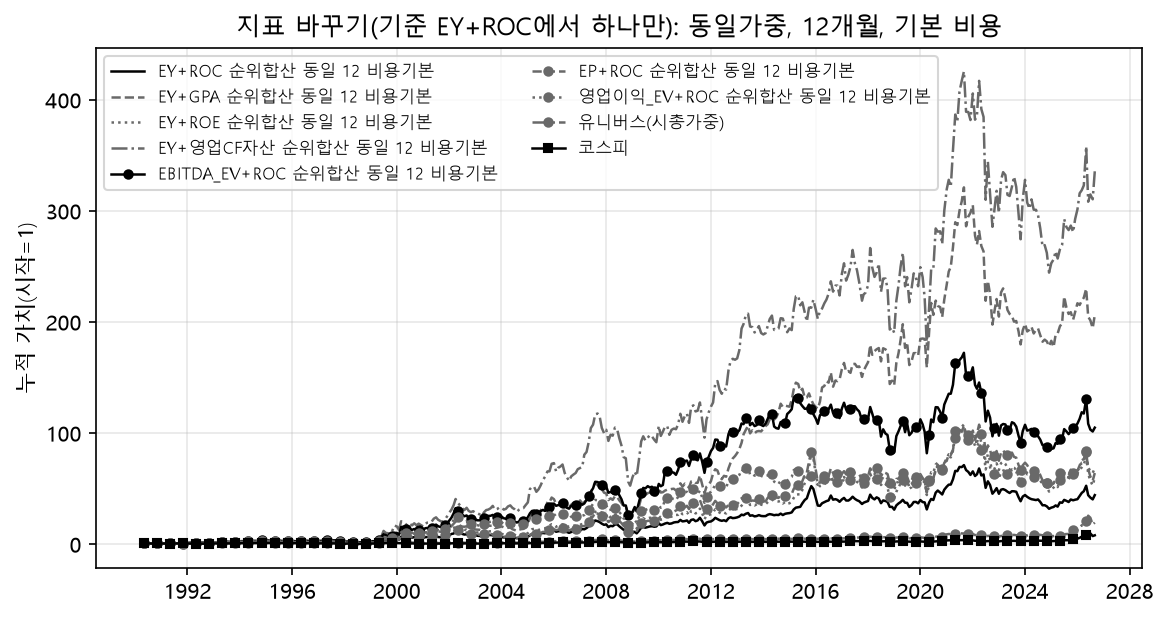

[요인 순서] 줄 3개. 샤프 가장 높음: ROC→EY / 동일 / 12 (0.416), 가장 낮음: EY→ROC / 동일 / 12 (0.146). 연환산 가장 높음: ROC→EY / 동일 / 12 (15.29%). MDD 가장 얕음: ROC→EY / 동일 / 12 (-64.78%).
  같은 기간 유니버스 시총가중 벤치마크보다 샤프가 높은 줄: 2/3개 (벤치 샤프 전체 0.223)


,,,,,개월,연환산,표준편차(연),샤프,MDD,회전율(전 기간),벤치 대비 연환산,정보비율,Carhart α(월),Carhart t(NW)
전략,비중,주기,비용,기간,,,,,,,,,,
EY+ROC 순위합산,동일,12,비용기본,전체,437.0000,0.1097,0.3334,0.2948,-0.7191,0.8131,0.0246,0.1337,0.0072,1.8668
EY→ROC,동일,12,비용기본,전체,437.0000,0.0576,0.3188,0.1463,-0.7501,0.7863,-0.0276,-0.0553,0.0028,0.9143
ROC→EY,동일,12,비용기본,전체,437.0000,0.1529,0.3220,0.4164,-0.6478,0.7785,0.0678,0.2681,0.0092,2.4684
벤치:유니버스(시총가중),-,0,비용0,전체,437.0000,0.0851,0.2724,0.2231,-0.6101,nan,0.0000,nan,0.0032,5.1880
벤치:코스피,-,0,비용0,전체,437.0000,0.0593,0.2697,0.1327,-0.7243,nan,-0.0258,-0.4442,0.0000,nan


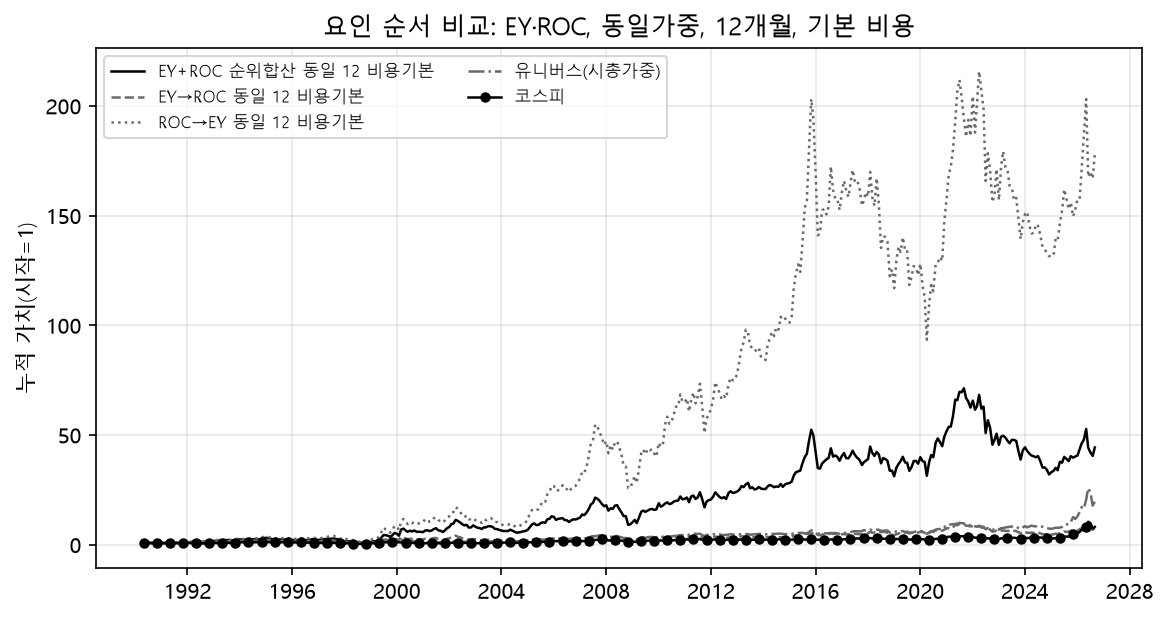

[거래비용 민감도] 줄 6개. 샤프 가장 높음: EY+ROC 순위합산 / 동일 / 1 / 비용0 (0.503), 가장 낮음: EY+ROC 순위합산 / 동일 / 12 / 비용2배 (0.263). 연환산 가장 높음: EY+ROC 순위합산 / 동일 / 1 / 비용0 (18.67%). MDD 가장 얕음: EY+ROC 순위합산 / 동일 / 1 / 비용0 (-55.55%).


  같은 기간 유니버스 시총가중 벤치마크보다 샤프가 높은 줄: 6/6개 (벤치 샤프 전체 0.223)


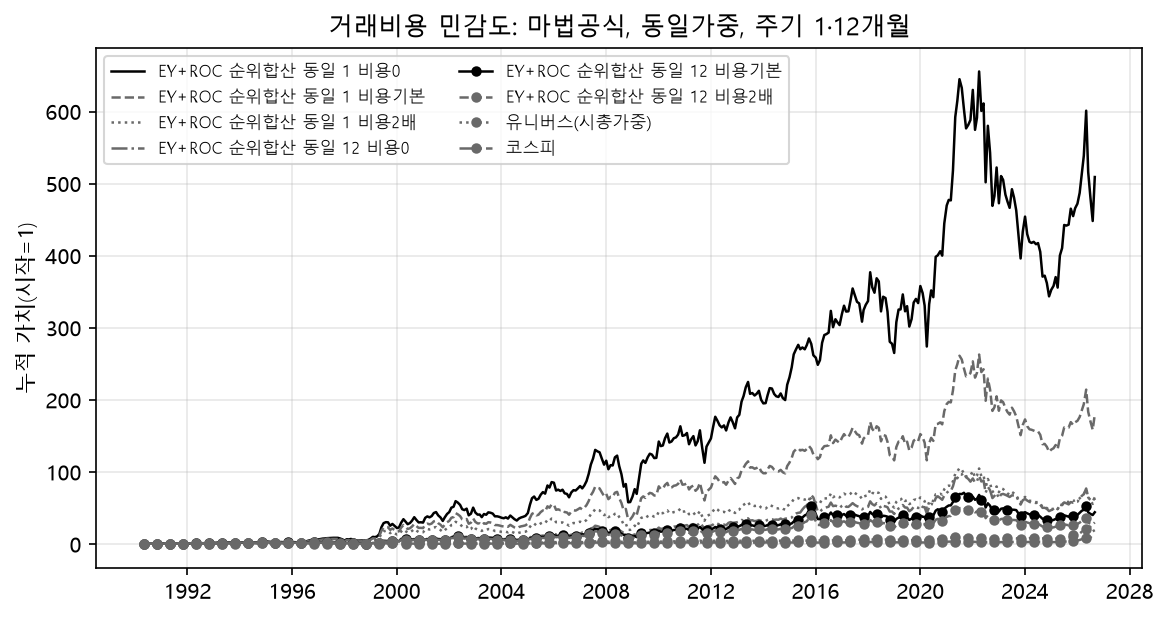

[기간별 (기준 전략과 벤치마크)] 줄 3개. 샤프 가장 높음: 2004-04~2017-03 / EY+ROC 순위합산 / 동일 / 12 (0.555), 가장 낮음: 2017-04~ / EY+ROC 순위합산 / 동일 / 12 (0.087). 연환산 가장 높음: 2004-04~2017-03 / EY+ROC 순위합산 / 동일 / 12 (15.26%). MDD 가장 얕음: 2017-04~ / EY+ROC 순위합산 / 동일 / 12 (-55.10%).
  같은 기간 유니버스 시총가중 벤치마크보다 샤프가 높은 줄: 2/3개 (벤치 샤프 1990-04~2004-03 -0.030, 2004-04~2017-03 0.395, 2017-04~ 0.559)


In [12]:
from IPython.display import Image
리포트 = Path.cwd().parent / "결과_전략수익률"
칸 = ["개월", "연환산", "표준편차(연)", "샤프", "MDD", "회전율(전 기간)", "벤치 대비 연환산", "정보비율", "Carhart α(월)", "Carhart t(NW)"]
제목 = {"1_비중": "비중 방식 (공통 기간)", "2_주기": "리밸런싱 주기", "3_지표": "지표 바꾸기 (순위합산)", "4_순서": "요인 순서", "5_비용": "거래비용 민감도", "6_기간": "기간별 (기준 전략과 벤치마크)"}
for n, t in 제목.items():
    x = pd.read_csv(리포트 / f"{n}.csv", encoding="utf-8-sig", index_col=list(range(5)))
    s = x[~x.index.get_level_values("전략").str.startswith("벤치:")]
    이름 = lambda i: " / ".join(str(v) for v in i if v not in ("비용기본", "전체", "공통"))
    print(f"[{t}] 줄 {len(s)}개. 샤프 가장 높음: {이름(s['샤프'].idxmax())} ({s['샤프'].max():.3f}), 가장 낮음: {이름(s['샤프'].idxmin())} ({s['샤프'].min():.3f}). "
          f"연환산 가장 높음: {이름(s['연환산'].idxmax())} ({s['연환산'].max():.2%}). MDD 가장 얕음: {이름(s['MDD'].idxmax())} ({s['MDD'].max():.2%}).")
    g = "기간" if "기간" in x.index.names else "기간칸"
    u = x.xs("벤치:유니버스(시총가중)", level="전략")["샤프"].groupby(level=g).first()  # 같은 기간의 유니버스 벤치마크 샤프
    print(f"  같은 기간 유니버스 시총가중 벤치마크보다 샤프가 높은 줄: {int((s['샤프'].to_numpy() > u.reindex(s.index.get_level_values(g)).to_numpy()).sum())}/{len(s)}개 (벤치 샤프 {', '.join(f'{k} {v:.3f}' for k, v in u.items())})")
    display(x[칸].style.set_caption(t).format(precision=4))
    if (리포트 / f"{n}.png").exists():
        display(Image(filename=리포트 / f"{n}.png"))

## 8. 남은 한계와 확인할 것
README '한계·미해결'과 `_진행기록_20261103.md` 맨 끝 '끝' 절을 본다.